# Tarea 2 · Parte 2 — Evaluación de modelos y extracción estructurada

**Pregunta:** ¿qué tan bien leen y escuchan los modelos abiertos documentos y entrevistas peruanas, y cuál conviene usar?

**Reglas que sigue este notebook**

- La muestra de evaluación se fijó **antes** de ver cualquier métrica: 10 documentos (3 impresos, 4 fotos, 3 manuscritos) y 10 clips (lecturas, testimonios, entrevistas en la calle y una con música), todos del corpus de la Parte 1.
- Las referencias (`texto_referencia`) son **transcripciones manuales** hechas mirando la imagen o escuchando el audio (`datos/referencias/*.txt`).
- Todos los modelos se evalúan sobre esos mismos 20 archivos y con su configuración por defecto: no se ajusta ningún parámetro mirando los resultados.
- Referencia y salida automática se normalizan igual (minúsculas, sin puntuación, sin muletillas como «eh», espacios simples) y en WER se quitan las marcas `[HABLANTE_n]`.

| Modalidad | Línea base | Otras configuraciones comparadas |
|---|---|---|
| Documentos (CER) | PaddleOCR 3.7 con valores por defecto | PaddleOCR con la configuración de la Parte 1 · EasyOCR 1.7 (alternativo) |
| Audio (WER, factor de tiempo real) | faster-whisper `small` en CPU | faster-whisper `large-v3-turbo` (Parte 1) · NVIDIA Parakeet TDT 0.6B v3 vía sherpa-onnx (alternativo) |
| Extracción estructurada | Qwen2.5-0.5B-Instruct local (transformers, CPU) | auditoría humana de 20 extracciones |

## 0. Preparación

In [1]:
import gc
import json
import os
import random
import re
import time
from datetime import date
from importlib.metadata import version
from pathlib import Path

import jiwer
import pandas as pd
import plotly.express as px
import plotly.io as pio
import soundfile as sf

import voz

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 80)
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
# Los pesos del LLM ya están en la caché local: no hace falta red.
os.environ["HF_HUB_OFFLINE"] = "1"

for paquete in ["paddleocr", "easyocr", "faster-whisper", "sherpa-onnx", "transformers", "torch", "jiwer"]:
    print(f"{paquete:15} {version(paquete)}")

paddleocr       3.7.0
easyocr         1.7.2
faster-whisper  1.2.1
sherpa-onnx     2.0.0
transformers    5.20.2
torch           2.14.1
jiwer           4.0.0


In [2]:
CARPETA_DATOS = Path("datos")
CARPETA_RAW = CARPETA_DATOS / "raw"
CARPETA_EVAL = CARPETA_RAW / "evaluacion"
CARPETA_EVAL.mkdir(parents=True, exist_ok=True)

MUESTRA_DOCS = ["doc_003", "doc_006", "doc_007", "doc_012", "doc_013", "doc_014", "doc_016", "doc_020", "doc_024", "doc_025"]
MUESTRA_CLIPS = ["clip_017", "clip_018", "clip_020", "clip_003", "clip_004", "clip_008", "clip_009", "clip_013", "clip_014", "clip_016"]

# Lista privada nombre real → seudónimo (fuera de Git): las salidas nuevas también se seudonimizan.
NOMBRES_PRIVADOS = json.loads((CARPETA_RAW / "seudonimos_privados.json").read_text(encoding="utf-8"))

documentos = pd.read_csv(CARPETA_DATOS / "documentos.csv", dtype={"texto_referencia": str})
audios = pd.read_csv(CARPETA_DATOS / "transcripciones.csv", dtype={"texto_referencia": str})
print(documentos.shape, audios.shape)

(25, 11) (21, 13)


## 1. Muestra de evaluación y referencias manuales

In [3]:
def leer_referencia(id_archivo):
    ruta = CARPETA_DATOS / "referencias" / f"{id_archivo}.txt"
    if not ruta.exists():
        return ""
    # La referencia manual pasa por la misma seudonimización que el texto automático.
    texto, _ = voz.seudonimizar(ruta.read_text(encoding="utf-8").strip(), NOMBRES_PRIVADOS)
    return texto


documentos["texto_referencia"] = documentos["id"].apply(lambda i: leer_referencia(i) if i in MUESTRA_DOCS else "")
audios["texto_referencia"] = audios["id"].apply(lambda i: leer_referencia(i) if i in MUESTRA_CLIPS else "")

muestra_docs = documentos[documentos["id"].isin(MUESTRA_DOCS)].copy()
muestra_clips = audios[audios["id"].isin(MUESTRA_CLIPS)].copy()
print("Documentos en la muestra por tipo:", muestra_docs["tipo"].value_counts().to_dict())
print("Clips en la muestra por tipo:     ", muestra_clips["tipo"].value_counts().to_dict())
print(f"Referencias manuales completas: {(muestra_docs['texto_referencia'] != '').sum()}/10 documentos, "
      f"{(muestra_clips['texto_referencia'] != '').sum()}/10 clips")

Documentos en la muestra por tipo: {'foto': 4, 'impreso': 3, 'manuscrito': 3}
Clips en la muestra por tipo:      {'entrevista_calle': 4, 'lectura_corpus': 3, 'testimonio': 2, 'entrevista_con_musica': 1}
Referencias manuales completas: 10/10 documentos, 10/10 clips


In [4]:
def normalizar(texto):
    texto = re.sub(r"\[HABLANTE_\d+\]", " ", str(texto))
    texto = texto.replace("[ilegible]", " ").lower()
    # Las etiquetas de seudónimo cuentan como una palabra: [PERSONA_4] → persona4
    texto = re.sub(r"\[(persona)_(\d+)\]", r"\1\2", texto)
    texto = re.sub(r"\[nombre\]", "nombre", texto)
    texto = re.sub(r"[^\wáéíóúüñ]+", " ", texto)
    # Muletillas que las personas transcriben y los modelos omiten: no son errores de reconocimiento.
    texto = re.sub(r"\b(eh+|ehm+|mm+|ah+)\b", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def cer(automatico, referencia):
    return jiwer.cer(normalizar(referencia), normalizar(automatico))


def wer(automatico, referencia):
    return jiwer.wer(normalizar(referencia), normalizar(automatico))


print(normalizar("[HABLANTE_1] ¿Me puede decir su nombre? [PERSONA_1], la Relijion."))

me puede decir su nombre persona1 la relijion


## 2. OCR: tres configuraciones sobre los mismos 10 documentos

Las tres leen la misma imagen preprocesada de la Parte 1 (orientación EXIF corregida, lado mayor ≤2500 px). Cada salida se guarda en `datos/raw/evaluacion/` para no repetir el cálculo.

In [5]:
def guardar(nombre, datos):
    (CARPETA_EVAL / nombre).write_text(json.dumps(datos, ensure_ascii=False, indent=1), encoding="utf-8")


def cargar(nombre):
    ruta = CARPETA_EVAL / nombre
    return json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else None


salidas_ocr = {}

In [6]:
# Línea base: PaddleOCR sin personalización (orientación de página, desdoblado y orientación de línea por defecto).
salidas_ocr["paddle_por_defecto"] = cargar("ocr_paddle_por_defecto.json")
if salidas_ocr["paddle_por_defecto"] is None:
    from paddleocr import PaddleOCR

    ocr = PaddleOCR(lang="es")
    resultado = {}
    for id_doc in MUESTRA_DOCS:
        inicio = time.time()
        prediccion = ocr.predict(str(CARPETA_RAW / "documentos" / "preprocesadas" / f"{id_doc}.jpg"))[0]
        resultado[id_doc] = {"texto": "\n".join(prediccion["rec_texts"]), "segundos": time.time() - inicio}
        print(f"{id_doc}: {resultado[id_doc]['segundos']:.0f} s")
    guardar("ocr_paddle_por_defecto.json", resultado)
    salidas_ocr["paddle_por_defecto"] = resultado
    del ocr
    gc.collect()

In [7]:
# Configuración de la Parte 1 (sin desdoblado ni clasificadores de orientación): ya calculada.
resultado = {}
for id_doc in MUESTRA_DOCS:
    respaldo = json.loads((CARPETA_RAW / "documentos" / "ocr" / f"{id_doc}.json").read_text(encoding="utf-8"))
    resultado[id_doc] = {"texto": "\n".join(respaldo["lineas"]), "segundos": respaldo["segundos"]}
salidas_ocr["paddle_parte1"] = resultado

In [8]:
# Alternativo: EasyOCR (detector CRAFT + reconocedor latino), otra arquitectura y otros datos de entrenamiento.
salidas_ocr["easyocr"] = cargar("ocr_easyocr.json")
if salidas_ocr["easyocr"] is None:
    import easyocr

    lector = easyocr.Reader(["es"], gpu=False)
    resultado = {}
    for id_doc in MUESTRA_DOCS:
        inicio = time.time()
        lineas = lector.readtext(str(CARPETA_RAW / "documentos" / "preprocesadas" / f"{id_doc}.jpg"), detail=0)
        resultado[id_doc] = {"texto": "\n".join(lineas), "segundos": time.time() - inicio}
        print(f"{id_doc}: {resultado[id_doc]['segundos']:.0f} s")
    guardar("ocr_easyocr.json", resultado)
    salidas_ocr["easyocr"] = resultado
    del lector
    gc.collect()

## 3. ASR: tres modelos sobre los mismos 10 clips

El factor de tiempo real es el tiempo de procesamiento dividido entre la duración del audio (menor que 1 = más rápido que escuchar el clip).

In [9]:
salidas_asr = {}

# Línea base: faster-whisper small en CPU, mismas opciones que la Parte 1 (VAD activado).
salidas_asr["whisper_small"] = cargar("asr_whisper_small.json")
if salidas_asr["whisper_small"] is None:
    from faster_whisper import WhisperModel

    modelo = WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=8)
    resultado = {}
    for id_clip in MUESTRA_CLIPS:
        inicio = time.time()
        frases, _ = voz.transcribir(modelo, CARPETA_RAW / "audio" / f"{id_clip}.wav")
        resultado[id_clip] = {"texto": " ".join(f["texto"] for f in frases), "segundos": time.time() - inicio}
        print(f"{id_clip}: {resultado[id_clip]['segundos']:.1f} s")
    guardar("asr_whisper_small.json", resultado)
    salidas_asr["whisper_small"] = resultado
    del modelo
    gc.collect()

In [10]:
# large-v3-turbo de la Parte 1: ya calculado (texto sin marcas de hablante).
resultado = {}
for id_clip in MUESTRA_CLIPS:
    respaldo = json.loads((CARPETA_RAW / "audio" / "asr" / f"{id_clip}.json").read_text(encoding="utf-8"))
    resultado[id_clip] = {"texto": " ".join(f["texto"] for f in respaldo["frases"]), "segundos": respaldo["segundos"]}
salidas_asr["whisper_large_v3_turbo"] = resultado

In [11]:
# Alternativo: NVIDIA Parakeet TDT 0.6B v3 (multilingüe, incluye español) en ONNX con sherpa-onnx.
# Parakeet no trae VAD: cortamos el audio en tramos con voz de hasta 20 s usando el mismo VAD Silero.
salidas_asr["parakeet_tdt_0.6b_v3"] = cargar("asr_parakeet.json")
if salidas_asr["parakeet_tdt_0.6b_v3"] is None:
    import sherpa_onnx
    from faster_whisper.audio import decode_audio
    from faster_whisper.vad import VadOptions, get_speech_timestamps

    carpeta_parakeet = Path("modelos") / "sherpa-onnx-nemo-parakeet-tdt-0.6b-v3-int8"
    reconocedor = sherpa_onnx.OfflineRecognizer.from_transducer(
        encoder=str(carpeta_parakeet / "encoder.int8.onnx"),
        decoder=str(carpeta_parakeet / "decoder.int8.onnx"),
        joiner=str(carpeta_parakeet / "joiner.int8.onnx"),
        tokens=str(carpeta_parakeet / "tokens.txt"),
        model_type="nemo_transducer",
        num_threads=8,
    )
    resultado = {}
    for id_clip in MUESTRA_CLIPS:
        inicio = time.time()
        audio = decode_audio(str(CARPETA_RAW / "audio" / f"{id_clip}.wav"), sampling_rate=16000)
        tramos = get_speech_timestamps(audio, VadOptions(min_silence_duration_ms=500, max_speech_duration_s=20))
        textos = []
        for tramo in tramos:
            flujo = reconocedor.create_stream()
            flujo.accept_waveform(16000, audio[tramo["start"]:tramo["end"]])
            reconocedor.decode_stream(flujo)
            textos.append(flujo.result.text.strip())
        resultado[id_clip] = {"texto": " ".join(textos), "segundos": time.time() - inicio}
        print(f"{id_clip}: {len(tramos)} tramos, {resultado[id_clip]['segundos']:.1f} s")
    guardar("asr_parakeet.json", resultado)
    salidas_asr["parakeet_tdt_0.6b_v3"] = resultado
    del reconocedor
    gc.collect()

In [12]:
# Las salidas nuevas pasan por la misma seudonimización que el corpus antes de compararlas o publicarlas.
for salidas in [salidas_ocr, salidas_asr]:
    for modelo, resultado in salidas.items():
        for id_archivo in resultado:
            resultado[id_archivo]["texto"], _ = voz.seudonimizar(resultado[id_archivo]["texto"], NOMBRES_PRIVADOS)
print("Ejemplo clip_017 por modelo:")
for modelo, resultado in salidas_asr.items():
    print(f"  {modelo:24} {resultado['clip_017']['texto'][:110]}")

Ejemplo clip_017 por modelo:
  whisper_small            Tenemos una película que se llama Sin Dienten Vive en los cocodrilos, que es una película muy divertida que ac
  whisper_large_v3_turbo   Tenemos una película que se llama Sin dientes viven los cocodrilos, que es una película muy divertida que acab
  parakeet_tdt_0.6b_v3     Tenemos una película que se llama Sin dienten me viven los cocodrilos, que es una película muy divertida que a


## 4. Métricas sobre la muestra (CER y WER)

In [13]:
duracion = audios.set_index("id")["duracion_seg"].to_dict()
tipo_doc = documentos.set_index("id")["tipo"].to_dict()
tipo_clip = audios.set_index("id")["tipo"].to_dict()
referencia_doc = documentos.set_index("id")["texto_referencia"].to_dict()
referencia_clip = audios.set_index("id")["texto_referencia"].to_dict()

filas = []
for modelo, resultado in salidas_ocr.items():
    for id_doc, salida in resultado.items():
        if referencia_doc[id_doc]:
            filas.append({"modelo": modelo, "id": id_doc, "tipo": tipo_doc[id_doc],
                          "cer": cer(salida["texto"], referencia_doc[id_doc]), "segundos": salida["segundos"]})
cer_por_doc = pd.DataFrame(filas)

filas = []
for modelo, resultado in salidas_asr.items():
    for id_clip, salida in resultado.items():
        if referencia_clip[id_clip]:
            filas.append({"modelo": modelo, "id": id_clip, "tipo": tipo_clip[id_clip],
                          "wer": wer(salida["texto"], referencia_clip[id_clip]),
                          "factor_tiempo_real": salida["segundos"] / duracion[id_clip]})
wer_por_clip = pd.DataFrame(filas)

faltan = (10 - muestra_docs["texto_referencia"].ne("").sum()) + (10 - muestra_clips["texto_referencia"].ne("").sum())
if faltan:
    print(f"Atención: faltan {faltan} referencias manuales; las métricas se calculan solo sobre las completas.")

In [14]:
if len(cer_por_doc) > 0:
    resumen_ocr = cer_por_doc.groupby("modelo").agg(cer_medio=("cer", "mean"), documentos=("id", "count"),
                                                    segundos_por_imagen=("segundos", "mean")).round(3)
    display(resumen_ocr)
    display(cer_por_doc.pivot_table(index="tipo", columns="modelo", values="cer", aggfunc="mean").round(3))
else:
    print("CER pendiente: no hay referencias manuales de documentos todavía.")

,cer_medio,documentos,segundos_por_imagen
modelo,,,
easyocr,0.298,10,33.155
paddle_parte1,0.161,10,14.983
paddle_por_defecto,0.295,10,19.166


modelo,easyocr,paddle_parte1,paddle_por_defecto
tipo,,,
foto,0.207,0.071,0.386
impreso,0.156,0.037,0.093
manuscrito,0.561,0.407,0.374


In [15]:
if len(wer_por_clip) > 0:
    resumen_asr = wer_por_clip.groupby("modelo").agg(wer_medio=("wer", "mean"), clips=("id", "count"),
                                                     factor_tiempo_real=("factor_tiempo_real", "mean")).round(3)
    display(resumen_asr)
    display(wer_por_clip.pivot_table(index="tipo", columns="modelo", values="wer", aggfunc="mean").round(3))
else:
    print("WER pendiente: no hay referencias manuales de audio todavía.")

,wer_medio,clips,factor_tiempo_real
modelo,,,
parakeet_tdt_0.6b_v3,0.213,10,0.091
whisper_large_v3_turbo,0.128,10,0.322
whisper_small,0.227,10,0.268


modelo,parakeet_tdt_0.6b_v3,whisper_large_v3_turbo,whisper_small
tipo,,,
entrevista_calle,0.405,0.273,0.379
entrevista_con_musica,0.161,0.063,0.206
lectura_corpus,0.025,0.017,0.067
testimonio,0.136,0.036,0.173


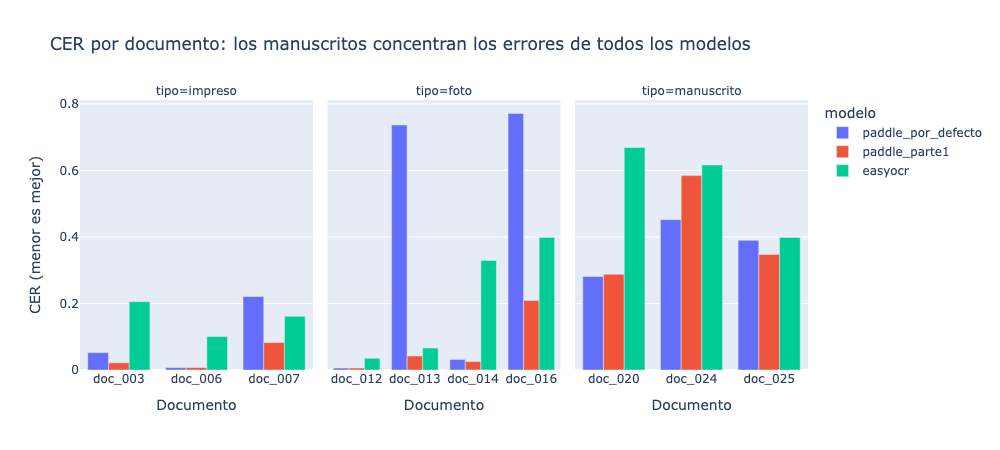

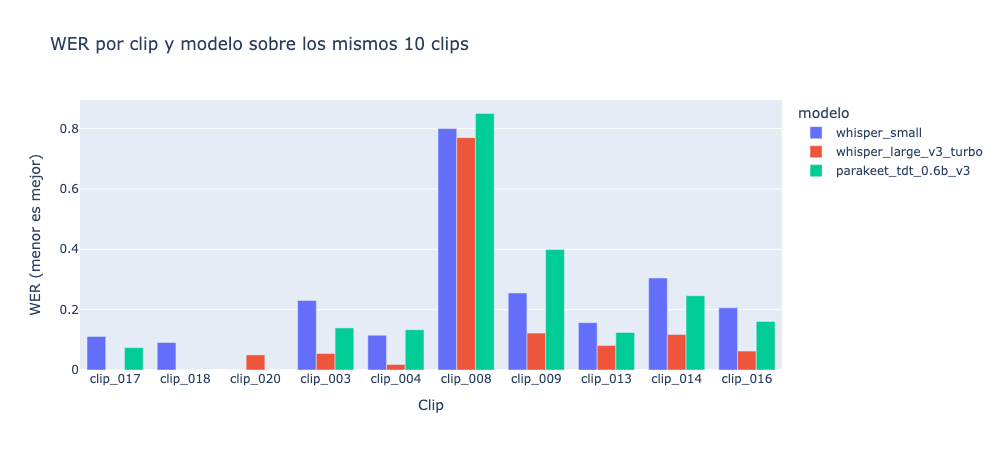

In [16]:
if len(cer_por_doc) > 0 and len(wer_por_clip) > 0:
    fig = px.bar(cer_por_doc, x="id", y="cer", color="modelo", barmode="group", facet_col="tipo",
                 title="CER por documento: los manuscritos concentran los errores de todos los modelos",
                 labels={"cer": "CER (menor es mejor)", "id": "Documento"})
    fig.update_xaxes(matches=None)
    fig.update_layout(width=1000, height=450)
    fig.show()
    fig = px.bar(wer_por_clip, x="id", y="wer", color="modelo", barmode="group",
                 title="WER por clip y modelo sobre los mismos 10 clips",
                 labels={"wer": "WER (menor es mejor)", "id": "Clip"})
    fig.update_layout(width=1000, height=450)
    fig.show()

## 5. Extracción estructurada con LLM

Qwen2.5-0.5B-Instruct corre local en CPU (sin enviar textos a ningún servicio). Recibe el texto seudonimizado de OCR o ASR y debe devolver **solo JSON** con `modalidad`, `tema` y `resumen`; en documentos además `emisor`, `fecha` y `monto`, y en audios `citas_clave` y `numero_hablantes`, con `null` cuando el dato no aparece. Decodificación determinista (sin muestreo).

In [17]:
MODELO_LLM = "Qwen/Qwen2.5-0.5B-Instruct"
ESQUEMA = {
    "documento": '{"modalidad": "documento", "tema": "...", "resumen": "...", "emisor": null, "fecha": null, "monto": null}',
    "audio": '{"modalidad": "audio", "tema": "...", "resumen": "...", "citas_clave": [], "numero_hablantes": null}',
}


def armar_mensajes(modalidad, texto):
    instrucciones = (
        f"Modalidad: {modalidad}. Texto obtenido por {'OCR' if modalidad == 'documento' else 'transcripción automática'}"
        f" (puede tener errores):\n\"\"\"\n{texto[:1500]}\n\"\"\"\n\n"
        f"Devuelve un JSON con exactamente estas claves:\n{ESQUEMA[modalidad]}\n"
        "Reglas: usa null si el dato no aparece en el texto; no inventes datos; el resumen tiene como máximo dos oraciones en español."
    )
    return [{"role": "system", "content": "Extraes información de documentos y entrevistas peruanas. Respondes solo con un objeto JSON válido."},
            {"role": "user", "content": instrucciones}]


def leer_json(respuesta):
    inicio, fin = respuesta.find("{"), respuesta.rfind("}")
    try:
        return json.loads(respuesta[inicio:fin + 1])
    except (json.JSONDecodeError, ValueError):
        return {"error_json": respuesta[:300]}

In [18]:
extraccion = cargar("extraccion_llm.json")
if extraccion is None:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tokenizador = AutoTokenizer.from_pretrained(MODELO_LLM)
    llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32)
    registros = []
    entradas = [("documento", f.id, f.texto_ocr) for f in documentos.itertuples()] + \
               [("audio", f.id, f.texto_asr) for f in audios.itertuples()]
    for modalidad, id_archivo, texto in entradas:
        inicio = time.time()
        prompt = tokenizador.apply_chat_template(armar_mensajes(modalidad, texto), tokenize=False, add_generation_prompt=True)
        tokens = tokenizador(prompt, return_tensors="pt")
        with torch.no_grad():
            generado = llm.generate(**tokens, max_new_tokens=220, do_sample=False)
        respuesta = tokenizador.decode(generado[0][tokens["input_ids"].shape[1]:], skip_special_tokens=True)
        registros.append({"id": id_archivo, "modalidad": modalidad, "campos": leer_json(respuesta),
                          "segundos": time.time() - inicio})
        print(f"{id_archivo}: {registros[-1]['segundos']:.0f} s")
    guardar("extraccion_llm.json", registros)
    extraccion = registros
    del llm
    gc.collect()

extraccion_llm = pd.DataFrame({
    "id": [r["id"] for r in extraccion],
    "modalidad": [r["modalidad"] for r in extraccion],
    "campos_json": [voz.seudonimizar(json.dumps(r["campos"], ensure_ascii=False), NOMBRES_PRIVADOS)[0] for r in extraccion],
    "modelo_llm": f"{MODELO_LLM} (transformers {version('transformers')}, CPU, greedy)",
    "fecha": date.today().isoformat(),
})
extraccion_llm.to_csv(CARPETA_DATOS / "extraccion_llm.csv", index=False)
json_validos = (~extraccion_llm["campos_json"].str.contains("error_json")).sum()
print(f"{len(extraccion_llm)} extracciones; JSON válido en {json_validos}")
extraccion_llm.head()

46 extracciones; JSON válido en 44


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia del Inca"", ""resumen"": ""Los Canc...","Qwen/Qwen2.5-0.5B-Instruct (transformers 5.20.2, CPU, greedy)",2026-10-26
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Religión y Política Nacional"", ""resumen""...","Qwen/Qwen2.5-0.5B-Instruct (transformers 5.20.2, CPU, greedy)",2026-10-26
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Religion and State of Peruans"", ""resumen...","Qwen/Qwen2.5-0.5B-Instruct (transformers 5.20.2, CPU, greedy)",2026-10-26
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Gobierno Peruviano"", ""resumen"": ""El Perú...","Qwen/Qwen2.5-0.5B-Instruct (transformers 5.20.2, CPU, greedy)",2026-10-26
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Historia Colonial"", ""resumen"": ""El texto...","Qwen/Qwen2.5-0.5B-Instruct (transformers 5.20.2, CPU, greedy)",2026-10-26


### 5.1 Auditoría humana de 20 extracciones

Se eligen al azar (semilla fija) 10 documentos y 10 audios. **Criterio de «completamente correcta»:** `modalidad` correcta; `tema` coherente con el texto; `resumen` fiel, sin hechos inventados; los campos presentes en el texto tienen el valor correcto y los ausentes valen `null`; no hay claves inventadas. Basta un campo mal para que la extracción cuente como incorrecta.

La revisión la hace una persona en `datos/auditoria_llm.csv` (columnas `correcta` = sí/no y `error_observado`).

In [19]:
azar = random.Random(2026)
ids_auditoria = azar.sample(list(documentos["id"]), 10) + azar.sample(list(audios["id"]), 10)
ruta_auditoria = CARPETA_DATOS / "auditoria_llm.csv"
if ruta_auditoria.exists():
    auditoria = pd.read_csv(ruta_auditoria, dtype=str).fillna("")
else:
    auditoria = extraccion_llm[extraccion_llm["id"].isin(ids_auditoria)][["id", "modalidad", "campos_json"]].copy()
    auditoria["correcta"] = ""
    auditoria["error_observado"] = ""
    auditoria.to_csv(ruta_auditoria, index=False)

revisadas = auditoria[auditoria["correcta"].str.strip() != ""]
if len(revisadas) == 0:
    print("Auditoría pendiente: completa la columna 'correcta' de datos/auditoria_llm.csv")
else:
    correctas = revisadas["correcta"].str.strip().str.lower().isin(["sí", "si", "s"]).sum()
    print(f"Acuerdo LLM–humano: {correctas}/{len(revisadas)} extracciones completamente correctas "
          f"({100 * correctas / len(revisadas):.0f} %)")
    display(revisadas[revisadas["correcta"].str.strip().str.lower().isin(["no", "n"])][["id", "error_observado"]])

Auditoría pendiente: completa la columna 'correcta' de datos/auditoria_llm.csv


## 6. Tabla comparativa

In [20]:
filas = []
for modelo, resultado in salidas_ocr.items():
    valor = cer_por_doc.loc[cer_por_doc["modelo"] == modelo, "cer"].mean() if len(cer_por_doc) else None
    segundos = sum(s["segundos"] for s in resultado.values()) / len(resultado)
    filas.append({"modalidad": "documento", "modelo": modelo, "metrica": "CER", "valor": valor,
                  "costo": f"{segundos:.0f} s por imagen (CPU)"})
for modelo, resultado in salidas_asr.items():
    valor = wer_por_clip.loc[wer_por_clip["modelo"] == modelo, "wer"].mean() if len(wer_por_clip) else None
    segundos = sum(s["segundos"] for s in resultado.values())
    total = sum(duracion[i] for i in resultado)
    filas.append({"modalidad": "audio", "modelo": modelo, "metrica": "WER", "valor": valor,
                  "costo": f"factor de tiempo real {segundos / total:.2f} (CPU)"})
comparativa = pd.DataFrame(filas)
comparativa.to_csv(CARPETA_DATOS / "metricas_modelos.csv", index=False)
comparativa

,modalidad,modelo,metrica,valor,costo
0,documento,paddle_por_defecto,CER,0.294881,19 s por imagen (CPU)
1,documento,paddle_parte1,CER,0.161339,15 s por imagen (CPU)
2,documento,easyocr,CER,0.297996,33 s por imagen (CPU)
3,audio,whisper_small,WER,0.227039,factor de tiempo real 0.25 (CPU)
4,audio,whisper_large_v3_turbo,WER,0.127661,factor de tiempo real 0.25 (CPU)
5,audio,parakeet_tdt_0.6b_v3,WER,0.212686,factor de tiempo real 0.09 (CPU)


## 6.1 Casos difíciles y reflexión por tipo

**Documentos.**
- *Impresos nítidos:* PaddleOCR con la configuración de la Parte 1 lee casi perfecto (CER 0,01–0,08); la configuración por defecto falla en la carta mecanografiada `doc_007` (0,22) y EasyOCR comete más errores de letra (0,10–0,21).
- *Fotos con sombras o inclinación:* aquí está la mayor diferencia entre configuraciones. PaddleOCR **por defecto** activa el desdoblado de página (UVDoc) y la corrección de orientación, pensados para hojas curvadas: en las placas `doc_013` y `doc_016` deforma la imagen y el CER sube a 0,74–0,77, contra 0,04–0,21 de la configuración de la Parte 1 sin esos módulos.
- *Manuscritos:* el peor tipo para todos los modelos (CER 0,28–0,67). Ninguno está entrenado para letra cursiva colonial ni para formularios llenados a mano. Además, en estos documentos la propia referencia humana es incierta (muchas palabras son difíciles de leer), así que su CER debe leerse con cautela.

**Audio.**
- *Lecturas limpias (OpenSLR):* los tres modelos quedan con WER bajo (0–0,11).
- *Testimonios y entrevistas en la calle:* large-v3-turbo es el más preciso (WER 0,02–0,12, salvo `clip_008`); small y Parakeet cometen entre 1,5 y 6 veces más errores en esos mismos clips.
- *Audio con música (`clip_016`, mariachis en Tarma):* contra lo esperado, el VAD separa bien la música y large-v3-turbo logra WER 0,06.
- *El caso realmente difícil fue `clip_008`* (entrevista en una feria): los tres modelos quedan con WER ≈0,8 porque el VAD solo detectó 28 de 90 s como voz; la entrevistada habla bajo y lejos del micrófono y esas frases se descartan antes de transcribir. El problema no es el reconocedor sino la detección de voz.
- *Opcional (quechua de Huaylas):* los 3 clips de Shansha quedan en reserva; no se evaluaron con MMS por el tamaño del modelo (≈4 GB) frente a la conexión y la RAM disponibles.

## 6.2 Decisión para un entorno real

| Necesidad | Elección | Por qué |
|---|---|---|
| OCR de impresos y fotos | **PaddleOCR 3.7 sin desdoblado ni orientación** (configuración de la Parte 1) | Menor CER (0,16) y el más rápido (15 s por imagen en CPU). La configuración por defecto empeora las fotos. |
| Manuscritos | Ninguno de los evaluados | CER demasiado alto: requiere un modelo de escritura a mano (HTR) o transcripción humana. |
| ASR con prioridad en precisión | **faster-whisper large-v3-turbo** | WER 0,13, casi la mitad que las alternativas, a un cuarto del tiempo real en CPU. |
| ASR con prioridad en latencia o costo | Parakeet TDT 0.6B v3 | Casi 3 veces más rápido (factor 0,09) con WER 0,21, mejor que Whisper small. |

Whisper small no conviene: es tan lento como turbo en esta máquina y comete casi el doble de errores. En los dos casos, la mejora más rentable sería ajustar el VAD para voces lejanas, no cambiar de modelo.

## 7. Exportación

Se actualizan `documentos.csv` y `transcripciones.csv` con la columna `texto_referencia` de la muestra (vacía en el resto).

In [21]:
documentos.to_csv(CARPETA_DATOS / "documentos.csv", index=False)
audios.to_csv(CARPETA_DATOS / "transcripciones.csv", index=False)

# Salida de cada modelo en la muestra, para comparar transcripciones en el dashboard.
filas = []
for modalidad, salidas, referencias, medir in [("documento", salidas_ocr, referencia_doc, cer), ("audio", salidas_asr, referencia_clip, wer)]:
    for modelo, resultado in salidas.items():
        for id_archivo, salida in resultado.items():
            valor = medir(salida["texto"], referencias[id_archivo]) if referencias[id_archivo] else None
            filas.append({"id": id_archivo, "modalidad": modalidad, "modelo": modelo, "texto": salida["texto"],
                          "metrica": "CER" if modalidad == "documento" else "WER", "valor": valor})
salidas_modelos = pd.DataFrame(filas)
salidas_modelos.to_csv(CARPETA_DATOS / "salidas_modelos.csv", index=False)
print(documentos.shape, audios.shape, extraccion_llm.shape, salidas_modelos.shape)

(25, 11) (21, 13) (46, 5) (60, 6)
